In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Load the household electricity dataset
file_path = r"D:\24cs013\DLunit\household_power_consumption.txt"

df = pd.read_csv(
    file_path,
    sep=";",
    na_values=["?"],
    low_memory=False
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print(df.head())


Dataset loaded successfully!
Dataset shape: (2075259, 9)
         Date      Time  Global_active_power  Global_reactive_power  Voltage  \
0  16/12/2006  17:24:00                4.216                  0.418   234.84   
1  16/12/2006  17:25:00                5.360                  0.436   233.63   
2  16/12/2006  17:26:00                5.374                  0.498   233.29   
3  16/12/2006  17:27:00                5.388                  0.502   233.74   
4  16/12/2006  17:28:00                3.666                  0.528   235.68   

   Global_intensity  Sub_metering_1  Sub_metering_2  Sub_metering_3  
0              18.4             0.0             1.0            17.0  
1              23.0             0.0             1.0            16.0  
2              23.0             0.0             2.0            17.0  
3              23.0             0.0             1.0            17.0  
4              15.8             0.0             1.0            17.0  


In [2]:

# Convert measurement columns to numeric values
measurement_columns = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

for col in measurement_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Combine date and time into one timestamp
df["Timestamp"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    dayfirst=True,
    errors="coerce"
)

# Sort records chronologically
df = df.sort_values("Timestamp").reset_index(drop=True)

# Remove rows with missing timestamps or measurements
df = df.dropna(
    subset=["Timestamp"] + measurement_columns
).copy()

# Keep 10,000 consecutive valid minute-level records
data = df[["Timestamp"] + measurement_columns].head(10000).copy()

print("Cleaned data shape:", data.shape)
print("Start time:", data["Timestamp"].iloc[0])
print("End time:", data["Timestamp"].iloc[-1])
print("Missing values:", data[measurement_columns].isnull().sum().sum())
print(data.head())


Cleaned data shape: (10000, 8)
Start time: 2006-12-16 17:24:00
End time: 2006-12-23 16:05:00
Missing values: 0
            Timestamp  Global_active_power  Global_reactive_power  Voltage  \
0 2006-12-16 17:24:00                4.216                  0.418   234.84   
1 2006-12-16 17:25:00                5.360                  0.436   233.63   
2 2006-12-16 17:26:00                5.374                  0.498   233.29   
3 2006-12-16 17:27:00                5.388                  0.502   233.74   
4 2006-12-16 17:28:00                3.666                  0.528   235.68   

   Global_intensity  Sub_metering_1  Sub_metering_2  Sub_metering_3  
0              18.4             0.0             1.0            17.0  
1              23.0             0.0             1.0            16.0  
2              23.0             0.0             2.0            17.0  
3              23.0             0.0             1.0            17.0  
4              15.8             0.0             1.0            17.0  


In [3]:

# Select the seven measurement features
feature_columns = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

# Split chronologically: 70% / 15% / 15%
train_df = data.iloc[:7000].copy()
val_df = data.iloc[7000:8500].copy()
test_df = data.iloc[8500:].copy()

print("Training records:", len(train_df))
print("Validation records:", len(val_df))
print("Testing records:", len(test_df))

print("\nTraining period:",
      train_df["Timestamp"].iloc[0],
      "to",
      train_df["Timestamp"].iloc[-1])

print("Validation period:",
      val_df["Timestamp"].iloc[0],
      "to",
      val_df["Timestamp"].iloc[-1])

print("Testing period:",
      test_df["Timestamp"].iloc[0],
      "to",
      test_df["Timestamp"].iloc[-1])


Training records: 7000
Validation records: 1500
Testing records: 1500

Training period: 2006-12-16 17:24:00 to 2006-12-21 14:05:00
Validation period: 2006-12-21 14:06:00 to 2006-12-22 15:05:00
Testing period: 2006-12-22 15:06:00 to 2006-12-23 16:05:00


In [4]:

# Normalize the seven input features
scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(
    train_df[feature_columns]
)

val_scaled = scaler.transform(
    val_df[feature_columns]
)

test_scaled = scaler.transform(
    test_df[feature_columns]
)

# Normalize the target separately (active power in kW)
target_scaler = MinMaxScaler()

train_target = target_scaler.fit_transform(
    train_df[["Global_active_power"]]
)

val_target = target_scaler.transform(
    val_df[["Global_active_power"]]
)

test_target = target_scaler.transform(
    test_df[["Global_active_power"]]
)

print("Training features:", train_scaled.shape)
print("Validation features:", val_scaled.shape)
print("Testing features:", test_scaled.shape)

print("Training target:", train_target.shape)
print("Normalization completed!")


Training features: (7000, 7)
Validation features: (1500, 7)
Testing features: (1500, 7)
Training target: (7000, 1)
Normalization completed!


In [5]:

lookback = 60

def make_sequences(features, targets, lookback):
    X, y = [], []

    for i in range(lookback, len(features)):
        X.append(features[i - lookback:i])
        y.append(targets[i])

    return np.array(X), np.array(y)

# Training sequences
X_train, y_train = make_sequences(
    train_scaled, train_target, lookback
)

# Include the preceding 60 minutes as context for validation
val_features_with_context = np.vstack([
    train_scaled[-lookback:],
    val_scaled
])

val_targets_with_context = np.vstack([
    train_target[-lookback:],
    val_target
])

X_val, y_val = make_sequences(
    val_features_with_context,
    val_targets_with_context,
    lookback
)

# Include the preceding 60 minutes as context for testing
test_features_with_context = np.vstack([
    train_scaled[-lookback:],
    val_scaled,
    test_scaled
])

test_targets_with_context = np.vstack([
    train_target[-lookback:],
    val_target,
    test_target
])

X_test, y_test = make_sequences(
    test_features_with_context,
    test_targets_with_context,
    lookback
)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)


X_train: (6940, 60, 7)
y_train: (6940, 1)
X_val: (1500, 60, 7)
y_val: (1500, 1)
X_test: (3000, 60, 7)
y_test: (3000, 1)


In [6]:

# Use the final 60 records before the test period as context
test_features_with_context = np.vstack([
    train_scaled[-lookback:],
    val_scaled,
    test_scaled
])

# Targets must contain ONLY test-period targets
X_test = []
y_test = []

for i in range(len(test_scaled)):
    # Window ends immediately before the target record
    start = len(train_scaled[-lookback:]) + len(val_scaled) + i - lookback
    end = start + lookback

    X_test.append(test_features_with_context[start:end])
    y_test.append(test_target[i])

X_test = np.array(X_test)
y_test = np.array(y_test)

print("Corrected X_test:", X_test.shape)
print("Corrected y_test:", y_test.shape)


Corrected X_test: (1500, 60, 7)
Corrected y_test: (1500, 1)


In [8]:

from tensorflow.keras.layers import GRU

print("GRU imported successfully!")


GRU imported successfully!


In [10]:

from tensorflow.keras.layers import GRU

tf.keras.utils.set_random_seed(42)

gru_model = Sequential([
    Input(shape=(lookback, len(feature_columns))),
    GRU(32),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])

gru_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

gru_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ gru (GRU)                            │ (None, 32)                  │           3,936 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,481 (17.50 KB)

 Trainable params: 4,481 (17.50 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:

# Predict electricity consumption
pred_scaled = gru_model.predict(X_test, verbose=0)

# Convert predictions and actual values back to kW
y_test_actual = target_scaler.inverse_transform(y_test)
gru_predictions = target_scaler.inverse_transform(pred_scaled)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test_actual, gru_predictions)
rmse = np.sqrt(mean_squared_error(y_test_actual, gru_predictions))

print("GRU Model Evaluation")
print("--------------------")
print(f"MAE:  {mae:.4f} kW")
print(f"RMSE: {rmse:.4f} kW")


GRU Model Evaluation
--------------------
MAE:  2.1039 kW
RMSE: 2.5105 kW


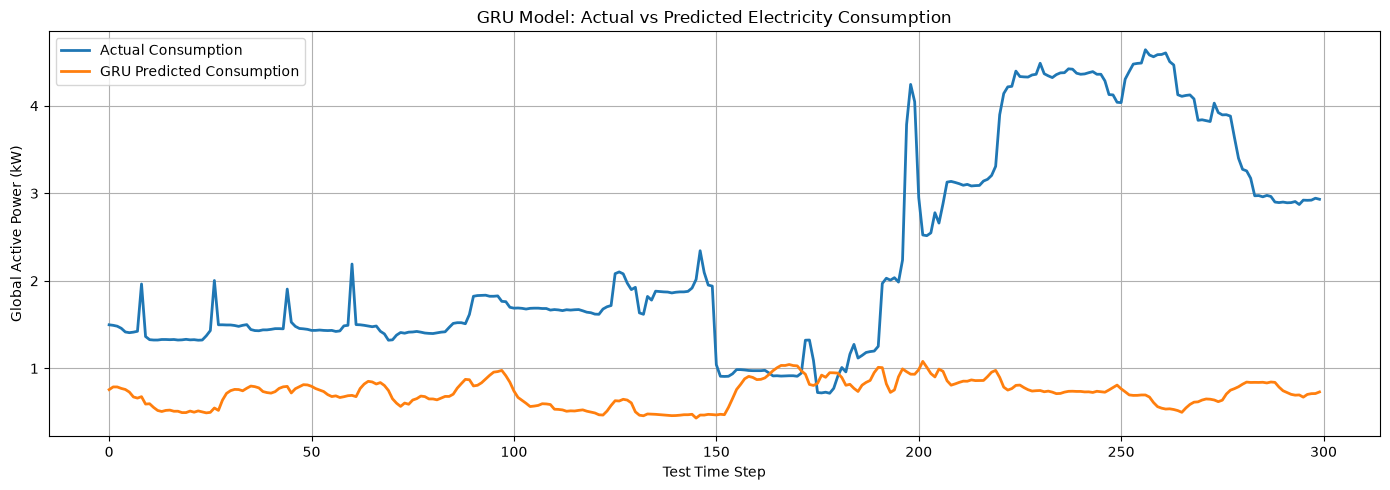

In [12]:

plt.figure(figsize=(14, 5))

plt.plot(
    y_test_actual[:300],
    label="Actual Consumption",
    linewidth=2
)

plt.plot(
    gru_predictions[:300],
    label="GRU Predicted Consumption",
    linewidth=2
)

plt.title("GRU Model: Actual vs Predicted Electricity Consumption")
plt.xlabel("Test Time Step")
plt.ylabel("Global Active Power (kW)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [13]:

print("TRAINING DATA")
print("Mean consumption:", round(float(train_df["Global_active_power"].mean()), 3), "kW")
print("Maximum consumption:", round(float(train_df["Global_active_power"].max()), 3), "kW")

print("\nTEST DATA")
print("Mean consumption:", round(float(y_test_actual.mean()), 3), "kW")
print("Maximum consumption:", round(float(y_test_actual.max()), 3), "kW")

# Simple baseline: predict the next value using the latest observed value
baseline_predictions = target_scaler.inverse_transform(
    X_test[:, -1, 0].reshape(-1, 1)
)

baseline_mae = mean_absolute_error(y_test_actual, baseline_predictions)
baseline_rmse = np.sqrt(
    mean_squared_error(y_test_actual, baseline_predictions)
)

print("\nPERSISTENCE BASELINE")
print(f"MAE:  {baseline_mae:.4f} kW")
print(f"RMSE: {baseline_rmse:.4f} kW")


TRAINING DATA
Mean consumption: 1.662 kW
Maximum consumption: 7.84 kW

TEST DATA
Mean consumption: 2.775 kW
Maximum consumption: 7.884 kW

PERSISTENCE BASELINE
MAE:  0.5058 kW
RMSE: 0.8236 kW


In [14]:

threshold = 3.0

train_high = (
    train_df["Global_active_power"] > threshold
).mean() * 100

test_high = (
    test_df["Global_active_power"] > threshold
).mean() * 100

print(f"Training readings above 3 kW: {train_high:.2f}%")
print(f"Test readings above 3 kW:     {test_high:.2f}%")


Training readings above 3 kW: 17.87%
Test readings above 3 kW:     41.60%


In [15]:

# Use more chronological records
data = df[["Timestamp"] + measurement_columns].head(50000).copy()

# Split chronologically: 70% training, 15% validation, 15% testing
train_end = int(len(data) * 0.70)
val_end = int(len(data) * 0.85)

train_df = data.iloc[:train_end].copy()
val_df = data.iloc[train_end:val_end].copy()
test_df = data.iloc[val_end:].copy()

print("Total records:", len(data))
print("Training records:", len(train_df))
print("Validation records:", len(val_df))
print("Testing records:", len(test_df))

print("\nTraining mean:",
      round(train_df["Global_active_power"].mean(), 3), "kW")
print("Validation mean:",
      round(val_df["Global_active_power"].mean(), 3), "kW")
print("Testing mean:",
      round(test_df["Global_active_power"].mean(), 3), "kW")


Total records: 50000
Training records: 35000
Validation records: 7500
Testing records: 7500

Training mean: 1.74 kW
Validation mean: 1.638 kW
Testing mean: 1.43 kW


In [16]:

# Normalize the seven input features
scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(train_df[feature_columns])
val_scaled = scaler.transform(val_df[feature_columns])
test_scaled = scaler.transform(test_df[feature_columns])

# Normalize the prediction target separately
target_scaler = MinMaxScaler()

train_target = target_scaler.fit_transform(
    train_df[["Global_active_power"]]
)

val_target = target_scaler.transform(
    val_df[["Global_active_power"]]
)

test_target = target_scaler.transform(
    test_df[["Global_active_power"]]
)

print("Training features:", train_scaled.shape)
print("Validation features:", val_scaled.shape)
print("Testing features:", test_scaled.shape)

print("Training target:", train_target.shape)
print("Validation target:", val_target.shape)
print("Testing target:", test_target.shape)


Training features: (35000, 7)
Validation features: (7500, 7)
Testing features: (7500, 7)
Training target: (35000, 1)
Validation target: (7500, 1)
Testing target: (7500, 1)


In [17]:

lookback = 60

def make_sequences(features, targets, lookback):
    X, y = [], []

    for i in range(lookback, len(features)):
        X.append(features[i - lookback:i])
        y.append(targets[i])

    return np.array(X), np.array(y)


# Training sequences
X_train, y_train = make_sequences(
    train_scaled, train_target, lookback
)

# Validation sequences with the last 60 training readings as context
val_features_context = np.vstack([
    train_scaled[-lookback:],
    val_scaled
])

val_targets_context = np.vstack([
    train_target[-lookback:],
    val_target
])

X_val, y_val = make_sequences(
    val_features_context, val_targets_context, lookback
)

# Test sequences with the preceding training and validation history
test_features_context = np.vstack([
    train_scaled[-lookback:],
    val_scaled,
    test_scaled
])

X_test = []
y_test = []

for i in range(len(test_scaled)):
    start = len(train_scaled[-lookback:]) + len(val_scaled) + i - lookback
    X_test.append(test_features_context[start:start + lookback])
    y_test.append(test_target[i])

X_test = np.array(X_test)
y_test = np.array(y_test)

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_val:  ", X_val.shape,   "| y_val:  ", y_val.shape)
print("X_test: ", X_test.shape,  "| y_test: ", y_test.shape)


X_train: (34940, 60, 7) | y_train: (34940, 1)
X_val:   (7500, 60, 7) | y_val:   (7500, 1)
X_test:  (7500, 60, 7) | y_test:  (7500, 1)


In [18]:

from tensorflow.keras.layers import GRU

tf.keras.utils.set_random_seed(42)

gru_model = Sequential([
    Input(shape=(lookback, len(feature_columns))),
    GRU(32),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])

gru_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

gru_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ gru_1 (GRU)                          │ (None, 32)                  │           3,936 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,481 (17.50 KB)

 Trainable params: 4,481 (17.50 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:

# Predict using the newly trained GRU model
pred_scaled = gru_model.predict(X_test, verbose=0)

# Convert scaled values back to kW
y_test_actual = target_scaler.inverse_transform(y_test)
gru_predictions = target_scaler.inverse_transform(pred_scaled)

# Calculate metrics
mae = mean_absolute_error(y_test_actual, gru_predictions)
rmse = np.sqrt(
    mean_squared_error(y_test_actual, gru_predictions)
)

print("GRU Model Evaluation (50,000 records)")
print("-------------------------------------")
print(f"MAE:  {mae:.4f} kW")
print(f"RMSE: {rmse:.4f} kW")


GRU Model Evaluation (50,000 records)
-------------------------------------
MAE:  1.3652 kW
RMSE: 1.5962 kW


In [20]:

# Predict the next reading using the latest observed consumption
baseline_scaled = X_test[:, -1, 0].reshape(-1, 1)

baseline_predictions = target_scaler.inverse_transform(
    baseline_scaled
)

baseline_mae = mean_absolute_error(
    y_test_actual, baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test_actual, baseline_predictions
))

print("Model Comparison")
print("----------------")
print(f"GRU MAE:       {mae:.4f} kW")
print(f"Baseline MAE:  {baseline_mae:.4f} kW")
print(f"GRU RMSE:      {rmse:.4f} kW")
print(f"Baseline RMSE: {baseline_rmse:.4f} kW")


Model Comparison
----------------
GRU MAE:       1.3652 kW
Baseline MAE:  0.1407 kW
GRU RMSE:      1.5962 kW
Baseline RMSE: 0.3849 kW


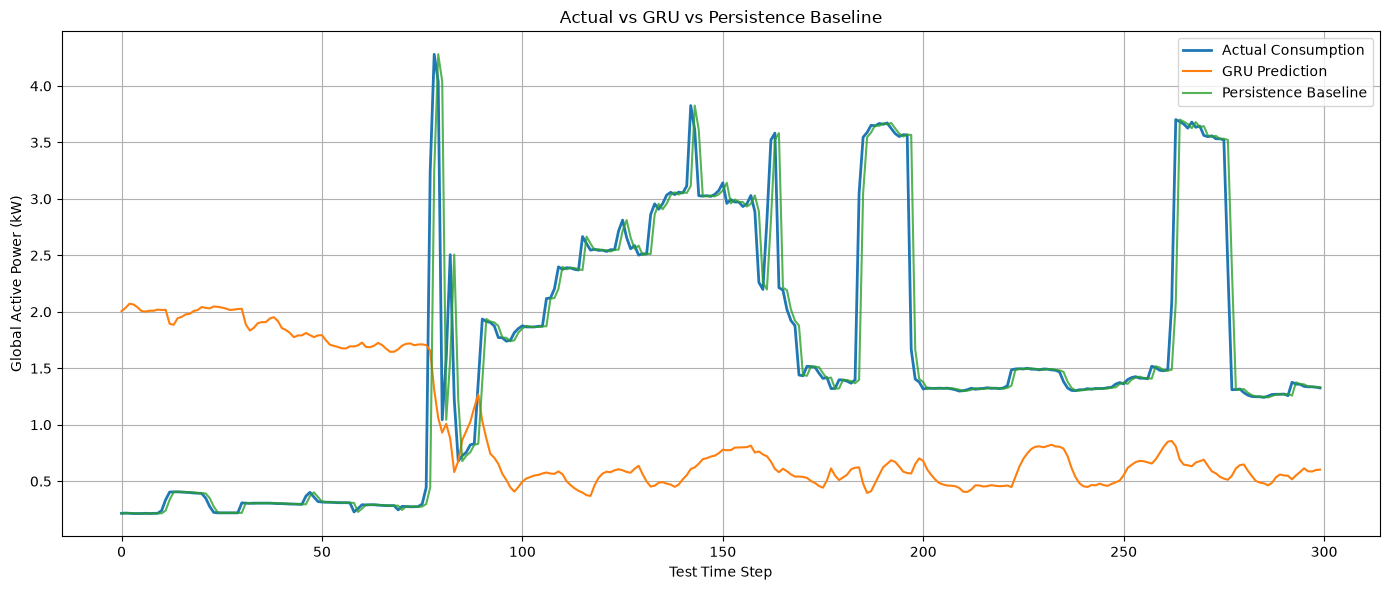

In [21]:

plt.figure(figsize=(14, 6))

plt.plot(
    y_test_actual[:300].ravel(),
    label="Actual Consumption",
    linewidth=2
)

plt.plot(
    gru_predictions[:300].ravel(),
    label="GRU Prediction",
    linewidth=1.5
)

plt.plot(
    baseline_predictions[:300].ravel(),
    label="Persistence Baseline",
    linewidth=1.5,
    alpha=0.8
)

plt.title("Actual vs GRU vs Persistence Baseline")
plt.xlabel("Test Time Step")
plt.ylabel("Global Active Power (kW)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [22]:

lookback = 120

X_train, y_train = make_sequences(
    train_scaled, train_target, lookback
)

val_features_context = np.vstack([
    train_scaled[-lookback:],
    val_scaled
])
val_targets_context = np.vstack([
    train_target[-lookback:],
    val_target
])
X_val, y_val = make_sequences(
    val_features_context, val_targets_context, lookback
)

test_features_context = np.vstack([
    train_scaled[-lookback:],
    val_scaled,
    test_scaled
])

X_test, y_test = [], []

for i in range(len(test_scaled)):
    start = len(train_scaled[-lookback:]) + len(val_scaled) + i - lookback
    X_test.append(test_features_context[start:start + lookback])
    y_test.append(test_target[i])

X_test = np.array(X_test)
y_test = np.array(y_test)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)


Training: (34880, 120, 7) (34880, 1)
Validation: (7500, 120, 7) (7500, 1)
Testing: (7500, 120, 7) (7500, 1)


In [23]:

tf.keras.utils.set_random_seed(42)

gru_model = Sequential([
    Input(shape=(lookback, len(feature_columns))),
    GRU(64),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])

gru_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

gru_model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ gru_2 (GRU)                          │ (None, 64)                  │          14,016 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 16)                  │           1,040 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 15,073 (58.88 KB)

 Trainable params: 15,073 (58.88 KB)

 Non-trainable params: 0 (0.00 B)

In [24]:

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

history = gru_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=64,
    callbacks=[early_stop],
    shuffle=False,
    verbose=1
)

print("Improved GRU training completed!")


Epoch 1/20
545/545 ━━━━━━━━━━━━━━━━━━━━ 20s 34ms/step - loss: 0.0054 - mae: 0.0494 - val_loss: 0.0033 - val_mae: 0.0332
Epoch 2/20
545/545 ━━━━━━━━━━━━━━━━━━━━ 19s 34ms/step - loss: 0.0030 - mae: 0.0345 - val_loss: 0.0028 - val_mae: 0.0262
Epoch 3/20
545/545 ━━━━━━━━━━━━━━━━━━━━ 18s 34ms/step - loss: 0.0026 - mae: 0.0304 - val_loss: 0.0025 - val_mae: 0.0237
Epoch 4/20
545/545 ━━━━━━━━━━━━━━━━━━━━ 18s 32ms/step - loss: 0.0024 - mae: 0.0293 - val_loss: 0.0023 - val_mae: 0.0225
Epoch 5/20
545/545 ━━━━━━━━━━━━━━━━━━━━ 18s 32ms/step - loss: 0.0023 - mae: 0.0280 - val_loss: 0.0022 - val_mae: 0.0221
Epoch 6/20
545/545 ━━━━━━━━━━━━━━━━━━━━ 18s 33ms/step - loss: 0.0023 - mae: 0.0281 - val_loss: 0.0021 - val_mae: 0.0210
Epoch 7/20
545/545 ━━━━━━━━━━━━━━━━━━━━ 19s 35ms/step - loss: 0.0021 - mae: 0.0263 - val_loss: 0.0021 - val_mae: 0.0218
Epoch 8/20
545/545 ━━━━━━━━━━━━━━━━━━━━ 18s 32ms/step - loss: 0.0022 - mae: 0.0274 - val_loss: 0.0021 - val_mae: 0.0218
Epoch 9/20
545/545 ━━━━━━━━━━━━━━━━━━━━ 

In [25]:

# Generate predictions on the test set
pred_scaled = gru_model.predict(X_test, verbose=0)

# Convert values back to kW
y_test_actual = target_scaler.inverse_transform(y_test)
gru_predictions = target_scaler.inverse_transform(pred_scaled)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test_actual, gru_predictions)
rmse = np.sqrt(
    mean_squared_error(y_test_actual, gru_predictions)
)

# Calculate persistence baseline on the same test set
baseline_predictions = target_scaler.inverse_transform(
    X_test[:, -1, 0].reshape(-1, 1)
)

baseline_mae = mean_absolute_error(
    y_test_actual, baseline_predictions
)
baseline_rmse = np.sqrt(
    mean_squared_error(y_test_actual, baseline_predictions)
)

print("FINAL MODEL COMPARISON")
print("----------------------")
print(f"GRU MAE:       {mae:.4f} kW")
print(f"Baseline MAE:  {baseline_mae:.4f} kW")
print(f"GRU RMSE:      {rmse:.4f} kW")
print(f"Baseline RMSE: {baseline_rmse:.4f} kW")


FINAL MODEL COMPARISON
----------------------
GRU MAE:       0.1686 kW
Baseline MAE:  0.1407 kW
GRU RMSE:      0.3554 kW
Baseline RMSE: 0.3849 kW


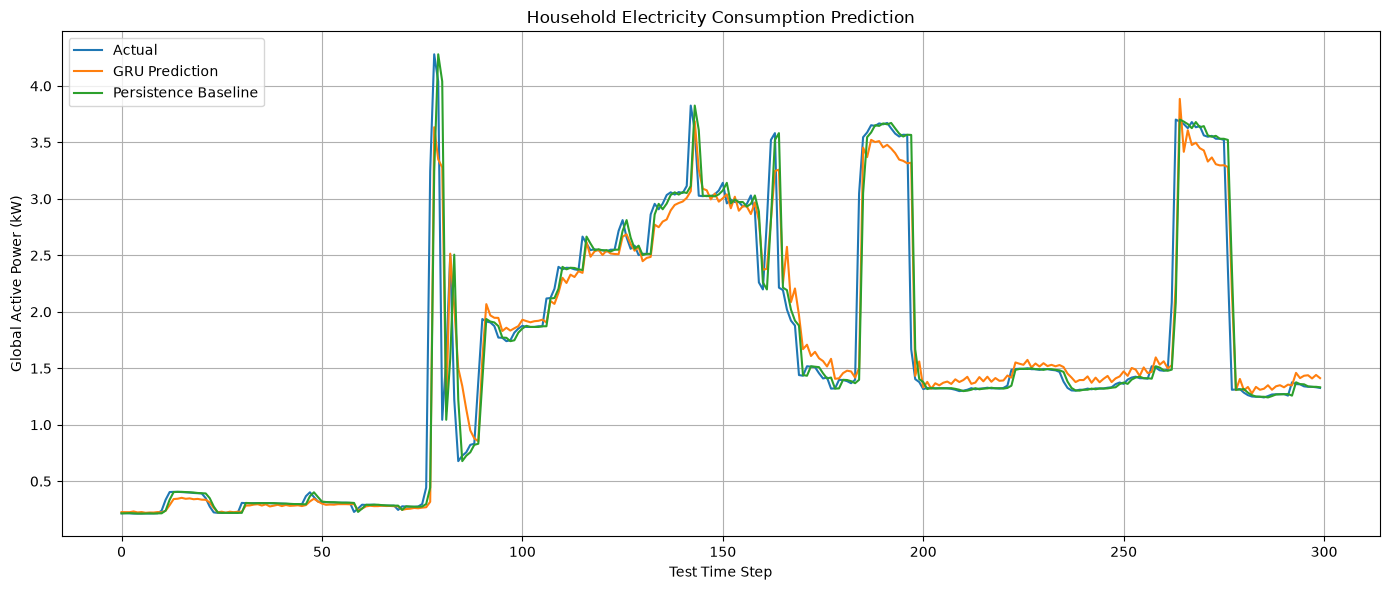

All final project artifacts saved successfully!
Folder: C:\Users\mukesh\electricity_model_artifacts
Files: ['evaluation_metrics.json', 'feature_scaler.joblib', 'feature_scaler.pkl', 'gru_model.keras', 'household_electricity_gru.keras', 'lstm_model.keras', 'metadata.json', 'prediction_comparison.png', 'target_scaler.joblib', 'target_scaler.pkl']


In [26]:

import os
import json
import joblib

# Create a folder for the final project files
output_dir = "electricity_model_artifacts"
os.makedirs(output_dir, exist_ok=True)

# Save the trained GRU model
gru_model.save(
    os.path.join(output_dir, "household_electricity_gru.keras")
)

# Save the scalers
joblib.dump(
    scaler,
    os.path.join(output_dir, "feature_scaler.pkl")
)

joblib.dump(
    target_scaler,
    os.path.join(output_dir, "target_scaler.pkl")
)

# Save evaluation results
metrics = {
    "model": "GRU",
    "dataset_records": 50000,
    "lookback": lookback,
    "gru_units": 64,
    "test_records": len(y_test),
    "gru_mae_kw": float(mae),
    "gru_rmse_kw": float(rmse),
    "baseline_mae_kw": float(baseline_mae),
    "baseline_rmse_kw": float(baseline_rmse)
}

with open(
    os.path.join(output_dir, "evaluation_metrics.json"),
    "w"
) as file:
    json.dump(metrics, file, indent=4)

# Save prediction graph
plt.figure(figsize=(14, 6))
plt.plot(y_test_actual[:300].ravel(), label="Actual")
plt.plot(gru_predictions[:300].ravel(), label="GRU Prediction")
plt.plot(
    baseline_predictions[:300].ravel(),
    label="Persistence Baseline"
)
plt.title("Household Electricity Consumption Prediction")
plt.xlabel("Test Time Step")
plt.ylabel("Global Active Power (kW)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(
    os.path.join(output_dir, "prediction_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("All final project artifacts saved successfully!")
print("Folder:", os.path.abspath(output_dir))
print("Files:", os.listdir(output_dir))



In [27]:

# Select unseen records after the first 50,000 valid records
unseen_df = df[["Timestamp"] + measurement_columns].iloc[50000:60000].copy()

print("Unseen data shape:", unseen_df.shape)
print("Start time:", unseen_df["Timestamp"].min())
print("End time:", unseen_df["Timestamp"].max())
print("Missing values:", unseen_df[feature_columns].isna().sum().sum())


Unseen data shape: (10000, 8)
Start time: 2007-01-20 10:49:00
End time: 2007-01-27 09:28:00
Missing values: 0


In [28]:

# Load the saved model and scalers
from tensorflow.keras.models import load_model
import joblib
import os

output_dir = "electricity_model_artifacts"

saved_model = load_model(
    os.path.join(output_dir, "household_electricity_gru.keras")
)

saved_scaler = joblib.load(
    os.path.join(output_dir, "feature_scaler.pkl")
)

saved_target_scaler = joblib.load(
    os.path.join(output_dir, "target_scaler.pkl")
)

# Normalize unseen input features using the original training scaler
unseen_scaled = saved_scaler.transform(
    unseen_df[feature_columns]
)

# Build sequences using the 120 previous readings
lookback = 120
X_unseen = []

for i in range(lookback, len(unseen_scaled)):
    X_unseen.append(
        unseen_scaled[i - lookback:i]
    )

X_unseen = np.array(X_unseen)

# Predict using the saved model
pred_scaled = saved_model.predict(X_unseen, verbose=0)

# Convert predictions back to kW
unseen_predictions = saved_target_scaler.inverse_transform(
    pred_scaled
).ravel()

# Actual values for comparison
unseen_actual = unseen_df["Global_active_power"].to_numpy()[lookback:]

print("Unseen input shape:", X_unseen.shape)
print("Number of predictions:", len(unseen_predictions))
print("First 5 predictions:", np.round(unseen_predictions[:5], 3))


Unseen input shape: (9880, 120, 7)
Number of predictions: 9880
First 5 predictions: [1.592 1.581 2.744 3.856 4.09 ]


In [29]:

# Calculate evaluation metrics on unseen data
unseen_mae = mean_absolute_error(
    unseen_actual, unseen_predictions
)

unseen_rmse = np.sqrt(
    mean_squared_error(unseen_actual, unseen_predictions)
)

print("UNSEEN DATA EVALUATION")
print("----------------------")
print("Number of predictions:", len(unseen_predictions))
print(f"MAE:  {unseen_mae:.4f} kW")
print(f"RMSE: {unseen_rmse:.4f} kW")

# Compare with the original test results
print("\nORIGINAL TEST vs UNSEEN DATA")
print(f"Original test MAE:  {mae:.4f} kW")
print(f"Unseen data MAE:    {unseen_mae:.4f} kW")
print(f"Original test RMSE: {rmse:.4f} kW")
print(f"Unseen data RMSE:   {unseen_rmse:.4f} kW")


UNSEEN DATA EVALUATION
----------------------
Number of predictions: 9880
MAE:  0.2246 kW
RMSE: 0.4392 kW

ORIGINAL TEST vs UNSEEN DATA
Original test MAE:  0.1686 kW
Unseen data MAE:    0.2246 kW
Original test RMSE: 0.3554 kW
Unseen data RMSE:   0.4392 kW


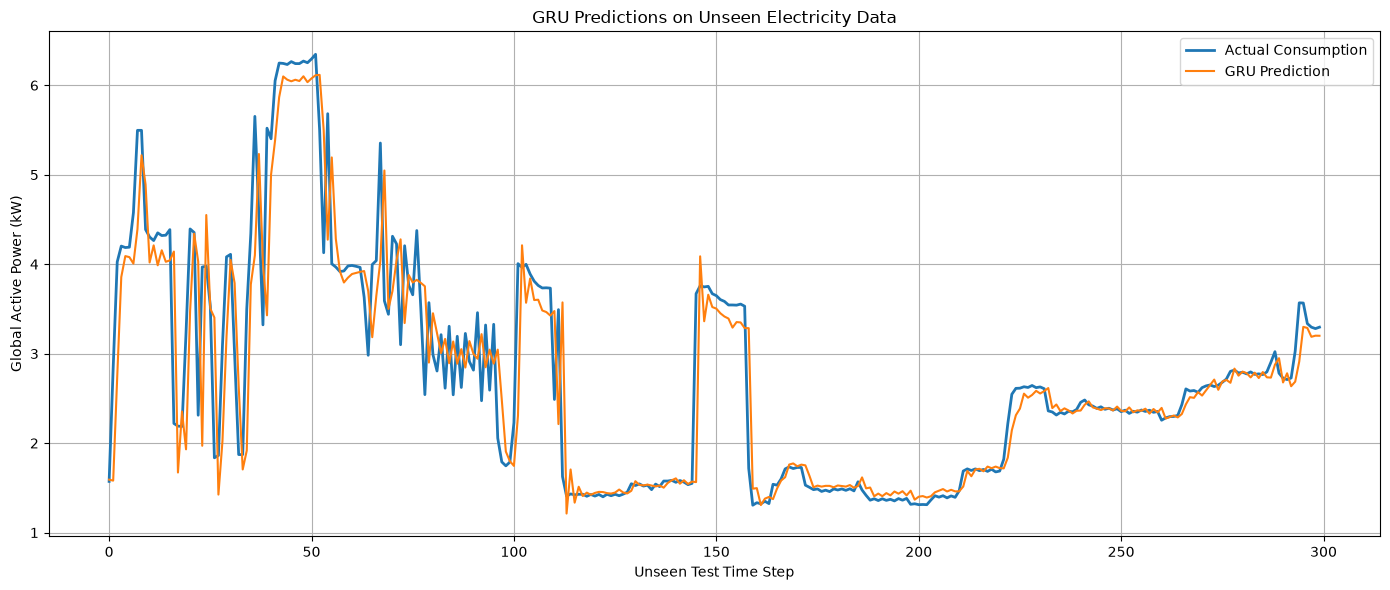

In [30]:

plt.figure(figsize=(14, 6))

plt.plot(
    unseen_actual[:300],
    label="Actual Consumption",
    linewidth=2
)

plt.plot(
    unseen_predictions[:300],
    label="GRU Prediction",
    linewidth=1.5
)

plt.title("GRU Predictions on Unseen Electricity Data")
plt.xlabel("Unseen Test Time Step")
plt.ylabel("Global Active Power (kW)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [34]:
model = Sequential()

In [36]:
model.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=["mae"]
)

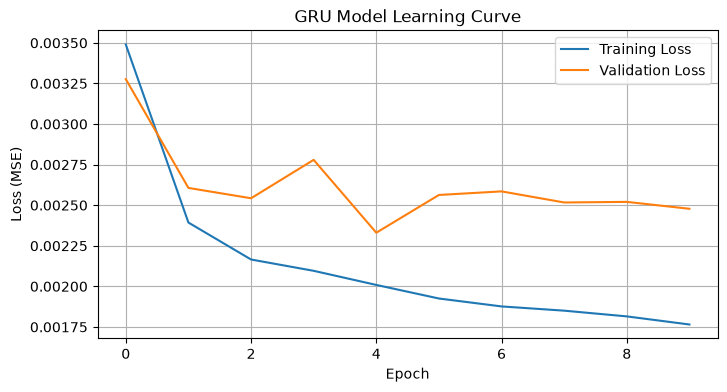

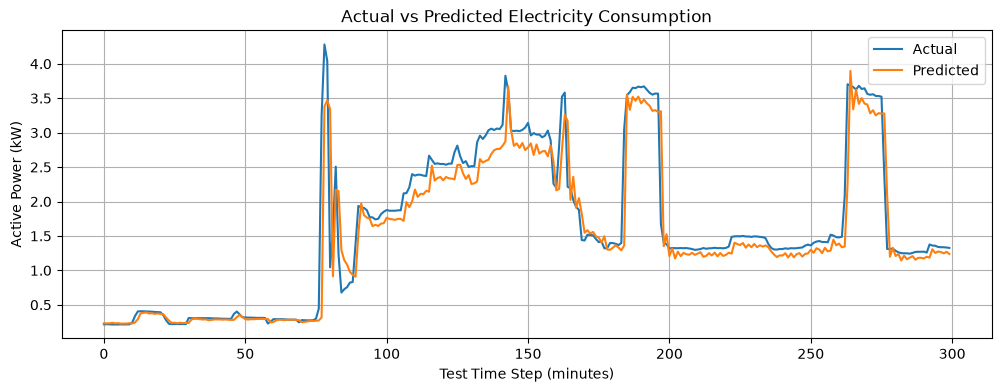

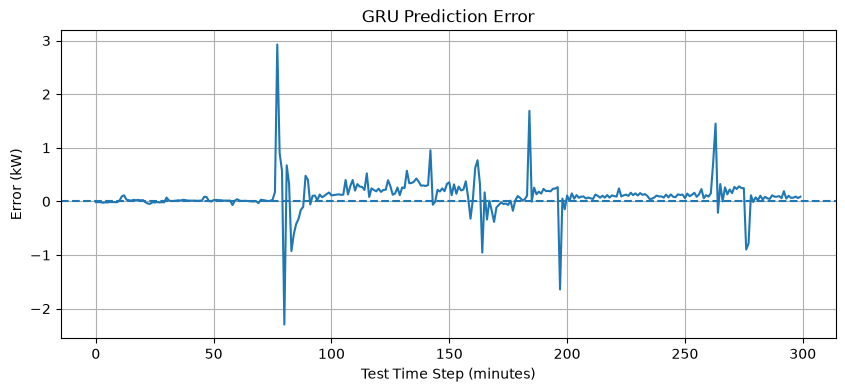

In [41]:

import matplotlib.pyplot as plt

# GRAPH 1: Training vs Validation Loss
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("GRU Model Learning Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.legend()
plt.grid(True)
plt.show()


# GRAPH 2: Actual vs Predicted Electricity Consumption
import numpy as np

y_pred_scaled = model.predict(X_test, verbose=0)

# If y_test and predictions are normalized using the same
# target scaler, convert them back to kW.
y_actual = target_scaler.inverse_transform(
    np.asarray(y_test).reshape(-1, 1)
).flatten()

y_predicted = target_scaler.inverse_transform(
    y_pred_scaled.reshape(-1, 1)
).flatten()

plt.figure(figsize=(12, 4))
plt.plot(y_actual[:300], label="Actual")
plt.plot(y_predicted[:300], label="Predicted")
plt.title("Actual vs Predicted Electricity Consumption")
plt.xlabel("Test Time Step (minutes)")
plt.ylabel("Active Power (kW)")
plt.legend()
plt.grid(True)
plt.show()


# GRAPH 3: Prediction Error
errors = y_actual - y_predicted

plt.figure(figsize=(10, 4))
plt.plot(errors[:300])
plt.axhline(0, linestyle="--")
plt.title("GRU Prediction Error")
plt.xlabel("Test Time Step (minutes)")
plt.ylabel("Error (kW)")
plt.grid(True)
plt.show()


     GRU MODEL PERFORMANCE
MAE       : 0.1953 kW
RMSE      : 0.3619 kW
R² Score  : 0.9037


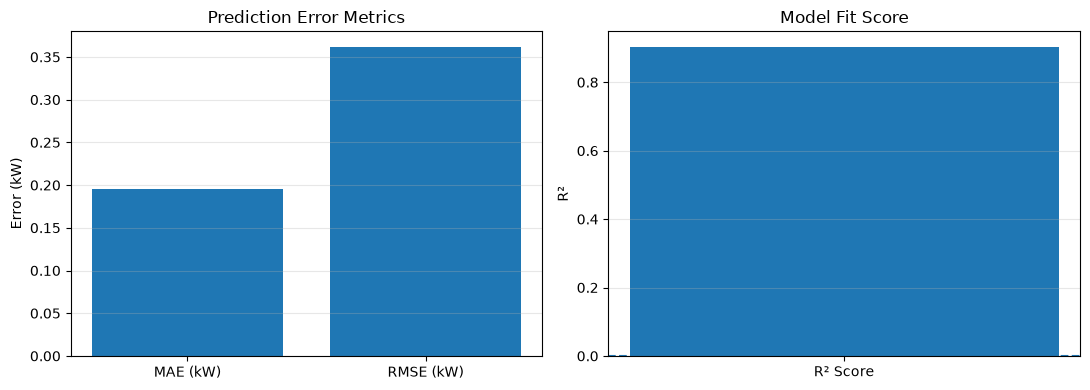

In [43]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Predict on the full test dataset
y_pred_scaled = model.predict(X_test, verbose=0)

# Convert values back to kW
y_actual = target_scaler.inverse_transform(
    np.asarray(y_test).reshape(-1, 1)
).flatten()

y_predicted = target_scaler.inverse_transform(
    y_pred_scaled.reshape(-1, 1)
).flatten()

# Calculate metrics
mae = mean_absolute_error(y_actual, y_predicted)
rmse = np.sqrt(mean_squared_error(y_actual, y_predicted))
r2 = r2_score(y_actual, y_predicted)

print("=" * 40)
print("     GRU MODEL PERFORMANCE")
print("=" * 40)
print(f"MAE       : {mae:.4f} kW")
print(f"RMSE      : {rmse:.4f} kW")
print(f"R² Score  : {r2:.4f}")
print("=" * 40)

# Display metric graphs
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].bar(
    ["MAE (kW)", "RMSE (kW)"],
    [mae, rmse]
)
axes[0].set_title("Prediction Error Metrics")
axes[0].set_ylabel("Error (kW)")
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(["R² Score"], [r2])
axes[1].set_title("Model Fit Score")
axes[1].set_ylabel("R²")
axes[1].axhline(0, linestyle="--")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [46]:

import numpy as np

sample_number = int(input("Enter sample number (0-1499): "))

if 0 <= sample_number < len(X_test):
    sample = X_test[sample_number:sample_number + 1]

    prediction_scaled = model.predict(sample, verbose=0)

    prediction = target_scaler.inverse_transform(
        prediction_scaled.reshape(-1, 1)
    )[0, 0]

    actual = target_scaler.inverse_transform(
        np.array(y_test[sample_number]).reshape(1, -1)
    )[0, 0]

    print("\n--- Electricity Prediction ---")
    print(f"Predicted consumption: {prediction:.3f} kW")
    print(f"Actual consumption:    {actual:.3f} kW")
    print(f"Absolute error:         {abs(actual - prediction):.3f} kW")
else:
    print("Please enter a sample number between 0 and 1499.")


Enter sample number (0-1499):  10



--- Electricity Prediction ---
Predicted consumption: 0.271 kW
Actual consumption:    0.240 kW
Absolute error:         0.031 kW
